# Visualisations of 4-D Marine Heatwave Events in the Northeast Pacific (GLORYS12)

This notebook plots the events tracked by [`02_track_extremes_4d.ipynb`](02_track_extremes_4d.ipynb), on the anomalies
written by [`01_preprocess_extremes.ipynb`](01_preprocess_extremes.ipynb). The events are volumes that live through
time, so the figures ask how deep an event reaches, how much heat it holds, and how much of it sea-surface temperature
would miss.

Two events run through the notebook. Both sit in the northeast Pacific in 2015, during the marine heatwave known as the
Blob (Bond et al., 2015), and they touch. The main event is the deep column, with a peak volume of 0.29 × 10¹⁵ m³ and
0.38 ZJ of excess heat. The second is the warm slab at the surface, with 0.16 × 10¹⁵ m³ and 1.08 ZJ. Each is found from a
point inside it on one day, because event IDs are labels and can change between runs.

The figures draw each event as an isosurface with `scipy` and `scikit-image`, which marEx already depends on, and
`matplotlib`. They need no graphics card or display, so they render on a compute node.

Compute: one compute node, with a local cluster of 16 single-threaded workers × 14 GB.

## Setup

In [1]:
import shutil
import subprocess
from getpass import getuser
from pathlib import Path

import cartopy.crs as ccrs
import cartopy.feature as cfeature
import dask
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xarray as xr
from IPython.display import Video
from matplotlib.colors import PowerNorm
from mpl_toolkits.mplot3d.art3d import Poly3DCollection
from scipy.ndimage import gaussian_filter
from skimage.measure import find_contours, marching_cubes

import marEx
import marEx.helper as hpc
from marEx.plotX import animate_event_levels, plot_event_depth_time, plot_event_levels, plot_event_summary

2026-11-02 22:12:58 - marEx - INFO - [PID:537248] - MarEx logging configured - Level: INFO, Mode: normal


In [2]:
scratch_dir = Path("/scratch") / getuser()[0] / getuser()
out_dir = scratch_dir / "marEx" / "examples" / "4d"  # where notebooks 01 and 02 wrote their output
plot_dir = out_dir / "plots"

# The two events drawn throughout, each named by a point inside it on one day
main_point = {"time": "2015-08-10", "lat": 44.2, "lon": -135.2, "depth": 750.0}
surface_point = {"time": "2015-08-10", "lat": 46.2, "lon": -131.4, "depth": 30.0}

render_box = {"lat": slice(32, 58), "lon": slice(-160, -120)}  # the part of the domain drawn as isosurfaces
movie_every = 3  # days between movie frames

# One compute node: 16 single-threaded workers x 14 GB = 224 GB. Movie frames render one per task without threads.
n_workers, threads_per_worker, memory_limit = 16, 1, "14GB"

In [3]:
plot_dir.mkdir(parents=True, exist_ok=True)

# memory_limit is set explicitly so the workers stay within the job's allocation (Dask otherwise sizes them from
# the whole node's memory).
client = hpc.start_local_cluster(
    n_workers=n_workers,
    threads_per_worker=threads_per_worker,
    memory_limit=memory_limit,
    scratch_dir=scratch_dir / "marEx" / "dask",
)

# Records wall time, peak memory, spill and worker restarts for each `monitor.stage(...)` block below
monitor = hpc.ResourceMonitor(client)

2026-11-02 22:13:08 - marEx.helper.cluster - INFO - [PID:537248] - Starting local Dask cluster with 16 workers, 1 threads each


2026-11-02 22:13:08 - marEx.helper.dask_config - INFO - [PID:537248] - Configuring Dask for HPC environment


2026-11-02 22:13:08 - marEx.helper.dask_config - INFO - [PID:537248] - Dask configuration completed


2026-11-02 22:13:08 - marEx.helper.cluster - INFO - [PID:537248] - System resources: 128 physical cores, 256 logical cores, 251.6GB total memory


2026-11-02 22:13:08 - marEx.helper.cluster - INFO - [PID:537248] - Memory limit per worker: 14.00 GB


2026-11-02 22:13:08 - marEx.helper.cluster - INFO - [PID:537248] - Starting Local cluster startup


2026-11-02 22:13:11 - marEx.helper.cluster - INFO - [PID:537248] - Completed Local cluster startup in 3.02s


Hostname: l20044
Forward Port: l20044:8787
Dashboard Link: localhost:8787/status
2026-11-02 22:13:11 - marEx.helper.cluster - INFO - [PID:537248] - Local cluster started successfully - Dashboard: http://127.0.0.1:8787/status


2026-11-02 22:13:11 - marEx.helper.cluster - INFO - [PID:537248] - After cluster startup - Memory Usage - RSS: 573.9MB, Virtual: 27293.2MB, Percent: 0.2%, Available: 244896.4MB


2026-11-02 22:13:11 - marEx.helper.resources - INFO - [PID:537248] - Cluster: 16 workers, 16 threads, memory_limit per worker [14.0] GB (224 GB total)


## 1. Load the Events

The per-event series are small and load directly. `ID_field` and the anomalies stay lazy, and each figure selects what
it needs before loading, so the 46 GB fields are never held in memory. The cell volume combines the cell areas with the
layer thicknesses from the interfaces.

In [4]:
extremes_ds = xr.open_zarr(out_dir / "extremes_glorys12_4d.zarr", chunks={})
events_ds = xr.open_zarr(out_dir / "events_4d.zarr", chunks={})
merges_ds = xr.open_zarr(out_dir / "merges_4d.zarr", chunks={}).load()

bounds = extremes_ds.depth_bnds.load()
thickness = xr.DataArray(bounds.values[:, 1] - bounds.values[:, 0], dims="depth", coords={"depth": extremes_ds.depth})
mask = extremes_ds.mask.compute()
cell_area = extremes_ds.cell_area.compute()
# m^3, land and sea floor NaN. Persisted, so the field stays out of every task graph and is read once.
cell_volume = (extremes_ds.cell_area * thickness).where(extremes_ds.mask).chunk({"depth": -1, "lat": -1, "lon": -1}).persist()
floor_depth = float(bounds.values[-1, 1])

volume = events_ds.volume.load()
centroid = events_ds.centroid.load()
depth_top, depth_centroid, depth_bottom = (events_ds[name].load() for name in ("depth_top", "depth_centroid", "depth_bottom"))
time_start, time_end = events_ds.time_start.load(), events_ds.time_end.load()
duration = (time_end - time_start).dt.days + 1  # both ends inclusive
peak_time = volume.idxmax("time")

main_id = int(events_ds.ID_field.sel(main_point, method="nearest"))
surface_id = int(events_ds.ID_field.sel(surface_point, method="nearest"))
assert main_id > 0 and surface_id > 0 and main_id != surface_id
main_peak = pd.Timestamp(peak_time.sel(ID=main_id).values)

for name, event_id in [("Main", main_id), ("Surface", surface_id)]:
    print(
        f"{name} event: ID {event_id}, {str(time_start.sel(ID=event_id).values)[:10]} to {str(time_end.sel(ID=event_id).values)[:10]}, "
        f"peak volume {float(volume.sel(ID=event_id).max()) / 1e15:.2f} x 10^15 m^3 on {str(peak_time.sel(ID=event_id).values)[:10]}"
    )

Main event: ID 400, 2014-10-07 to 2016-07-03, peak volume 0.29 x 10^15 m^3 on 2015-08-10
Surface event: ID 392, 2014-09-21 to 2016-12-31, peak volume 0.16 x 10^15 m^3 on 2015-07-11


## 2. The Whole Population

Each marker is one of the 912 events. The input stops at 1150 m, so an event that reaches that level (a hollow marker,
31% of events on their peak day) has a volume and a depth that are lower bounds. Depth is coloured at the day of peak
volume. Most events are brief, and most are deep: the median lasts 12 days, the median centroid is at 699 m, and only 5% centre
above 100 m. The 82 events lasting 90 days or more span a median of 482 m at peak, and the others 175 m. Durations are lower
bounds too for the 14 events that start on the first day of the record and the 39 that end on its last, event 392 among
them.

The depth skew may partly reflect the volume filter, which applies one threshold at every level. Its
2.5 × 10¹² m³ is a patch of about 14,800 km² on the 171 m thick bottom level and about 25,000 km² through the top 100 m.
The median footprint at peak is 33,000 km² for events centred below 500 m and 188,000 km² for those centred above 100 m.

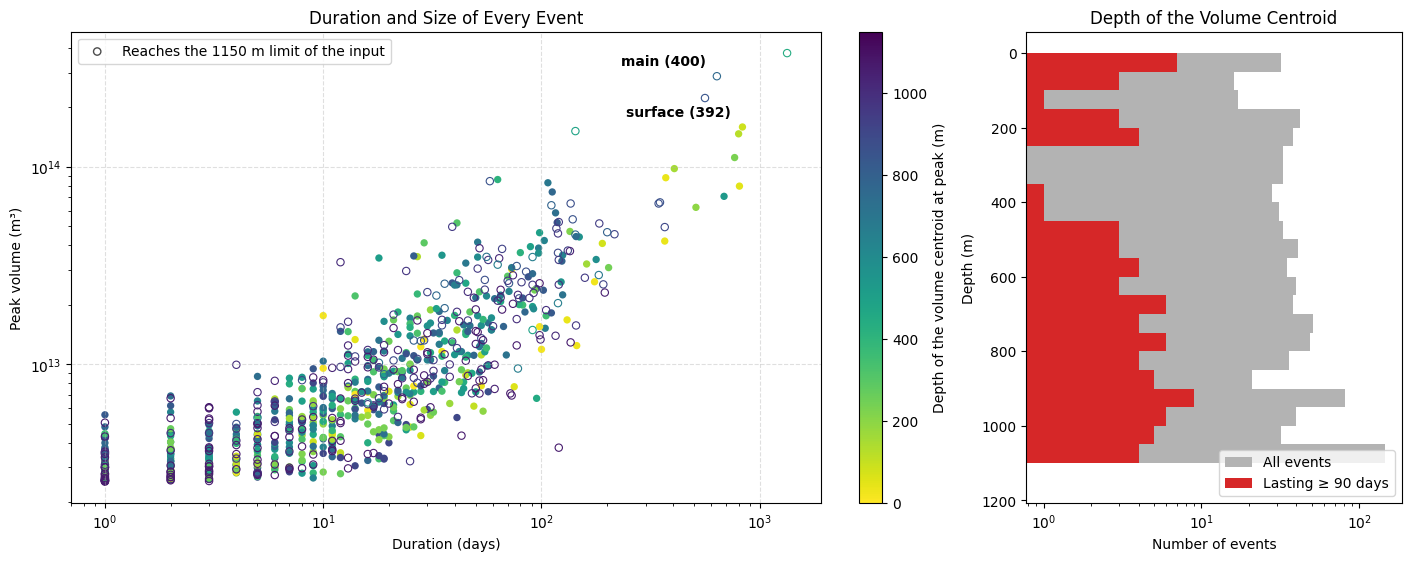

In [5]:
at_peak = {"time": peak_time}
centroid_depth_at_peak = depth_centroid.sel(**at_peak).values
reaches_floor = depth_bottom.sel(**at_peak).values >= floor_depth - 1
peak_volume = volume.max("time").values

fig, (ax_scatter, ax_hist) = plt.subplots(1, 2, figsize=(14, 5.5), width_ratios=[2, 1], layout="constrained")
for hollow in (False, True):
    pick = reaches_floor == hollow
    scatter = ax_scatter.scatter(
        duration.values[pick],
        peak_volume[pick],
        c=None if hollow else centroid_depth_at_peak[pick],
        edgecolors=plt.cm.viridis_r(centroid_depth_at_peak[pick] / floor_depth) if hollow else "none",
        facecolors="none" if hollow else None,
        s=28,
        linewidths=0.8,
        cmap=None if hollow else "viridis_r",
        vmin=None if hollow else 0,
        vmax=None if hollow else floor_depth,
    )
    if not hollow:
        fig.colorbar(scatter, ax=ax_scatter, label="Depth of the volume centroid at peak (m)")
for event_id, label in [(main_id, "main"), (surface_id, "surface")]:
    x, y = float(duration.sel(ID=event_id)), float(volume.sel(ID=event_id).max())
    ax_scatter.annotate(f"{label} ({event_id})", (x, y), xytext=(-8, 8), textcoords="offset points", ha="right", fontweight="bold")
ax_scatter.set(
    xscale="log", yscale="log", xlabel="Duration (days)", ylabel="Peak volume (m³)", title="Duration and Size of Every Event"
)
ax_scatter.grid(True, which="major", linestyle="--", alpha=0.4)
ax_scatter.scatter([], [], facecolors="none", edgecolors="0.3", s=28, label=f"Reaches the {floor_depth:.0f} m limit of the input")
ax_scatter.legend(loc="upper left")

bins = np.linspace(0, floor_depth, 24)
ax_hist.hist(centroid_depth_at_peak, bins=bins, orientation="horizontal", color="0.7", label="All events")
ax_hist.hist(
    centroid_depth_at_peak[duration.values >= 90], bins=bins, orientation="horizontal", color="tab:red", label="Lasting ≥ 90 days"
)
ax_hist.invert_yaxis()
ax_hist.set(xscale="log", xlabel="Number of events", ylabel="Depth (m)", title="Depth of the Volume Centroid")
ax_hist.legend()
plt.show()

## 3. Events as Isosurfaces

`draw_scene` smooths the mask of each event, extracts its isosurface with marching cubes and colours every triangle by
the local temperature anomaly. The surface is lit in the plot's stretched coordinates, so depth stays legible at this
vertical exaggeration. The floor shows the input's lower limit, where the deepest level is ocean, with each event's
footprint cast on it, and the outline at the top is the coast.

All triangles go into one collection, so `matplotlib` sorts them together and the events occlude each other correctly.

In [6]:
BACKGROUND = "#080c18"
ANOMALY_NORM = PowerNorm(0.5, vmin=0, vmax=2.5)
ANOMALY_CMAP = plt.get_cmap("inferno")
EVENT_TINT = {main_id: (0.75, 0.35, 0.95), surface_id: (1.0, 0.55, 0.15)}  # footprint colours on the floor
BOX_HEIGHT = 10.0  # height of the drawn box, in degrees of latitude on the plot

box_mask = mask.sel(**render_box)
box_lat, box_lon, box_depth = box_mask.lat.values, box_mask.lon.values, box_mask.depth.values
box_aspect = np.array([(box_lon[-1] - box_lon[0]) * np.cos(np.deg2rad(box_lat.mean())), box_lat[-1] - box_lat[0], BOX_HEIGHT])
exaggeration = 111.2e3 * (BOX_HEIGHT / floor_depth)
wet_at_floor = box_mask.isel(depth=-1).values
wet_at_surface = box_mask.isel(depth=0).values


def event_triangles(in_event, anomaly, step=2):
    """Triangles (lon, lat, -depth) of the smoothed event surface, their anomaly colours and smooth normals."""
    smoothed = gaussian_filter(in_event[:, ::step, ::step].astype("f4"), sigma=(0.6, 1.0, 1.0))
    if smoothed.max() < 0.5:
        return None
    vertices, faces, _, _ = marching_cubes(np.pad(smoothed, 1), 0.5)
    k, j, i = (vertices - 1).T
    xyz = np.c_[
        np.interp(i * step, np.arange(box_lon.size), box_lon),
        np.interp(j * step, np.arange(box_lat.size), box_lat),
        -np.interp(k, np.arange(box_depth.size), box_depth),
    ]
    plotted = xyz * box_aspect / np.array([box_lon[-1] - box_lon[0], box_lat[-1] - box_lat[0], floor_depth])
    face_normals = np.cross(plotted[faces[:, 1]] - plotted[faces[:, 0]], plotted[faces[:, 2]] - plotted[faces[:, 0]])
    vertex_normals = np.zeros_like(plotted)
    for corner in range(3):
        np.add.at(vertex_normals, faces[:, corner], face_normals)

    centres = (vertices - 1)[faces].mean(axis=1)
    level = np.clip(centres[:, 0].round().astype(int), 0, box_depth.size - 1)
    row = np.clip((centres[:, 1] * step).round().astype(int), 0, box_lat.size - 1)
    column = np.clip((centres[:, 2] * step).round().astype(int), 0, box_lon.size - 1)
    colours = ANOMALY_CMAP(ANOMALY_NORM(np.clip(np.nan_to_num(anomaly[level, row, column]), 0.02, None)))[:, :3]
    return xyz[faces], colours, vertex_normals[faces].mean(axis=1)


def lit(colours, normals, camera):
    """Two-sided diffuse and specular shading for a camera (elevation, azimuth) in degrees."""
    elevation, azimuth = np.deg2rad(camera)
    view = np.array([np.cos(elevation) * np.cos(azimuth), np.cos(elevation) * np.sin(azimuth), np.sin(elevation)])
    light = np.array([-0.45, -0.55, 0.7]) / np.linalg.norm([-0.45, -0.55, 0.7])
    halfway = (light + view) / np.linalg.norm(light + view)
    normals = normals / np.maximum(np.linalg.norm(normals, axis=1, keepdims=True), 1e-12)
    normals = normals * np.where(normals @ view < 0, -1.0, 1.0)[:, None]
    diffuse = np.clip(normals @ light, 0, 1)[:, None]
    specular = np.clip(normals @ halfway, 0, 1)[:, None] ** 24
    return np.clip(colours * (0.38 + 0.72 * diffuse) + 0.28 * specular, 0, 1)


def grid_quads(where, z, step):
    """Two triangles per grid box of `where` (coarsened by `step`) at height z, with their row and column."""
    rows, columns = np.nonzero(where[::step, ::step])
    lat, lon = box_lat[::step], box_lon[::step]
    dlat, dlon = lat[1] - lat[0], lon[1] - lon[0]
    x0, y0 = lon[columns], lat[rows]
    corners = np.stack([np.c_[x0, y0], np.c_[x0 + dlon, y0], np.c_[x0 + dlon, y0 + dlat], np.c_[x0, y0 + dlat]], axis=1)
    corners = np.concatenate([corners, np.full((*corners.shape[:2], 1), z)], axis=2)
    triangles = np.r_[corners[:, [0, 1, 2]], corners[:, [0, 2, 3]]]
    return triangles, np.r_[rows, rows] * step, np.r_[columns, columns] * step


def draw_scene(fig, rect, ids, anomaly, title=None, camera=(22, -62), zoom=1.25, axes_visible=True):
    """Draw the main and surface events of one day, (depth, lat, lon) arrays on `render_box`, into a 3-D axes."""
    ax = fig.add_axes(rect, projection="3d", computed_zorder=False, facecolor=BACKGROUND)

    floor, rows, columns = grid_quads(wet_at_floor, -floor_depth, step=3)
    floor_colours = np.tile([0.11, 0.16, 0.26], (len(floor), 1))
    triangles, colours = [floor], [floor_colours]
    for event_id, tint in EVENT_TINT.items():
        in_event = ids == event_id
        footprint = in_event.any(axis=0)[rows, columns][:, None] * 0.55
        floor_colours *= 1 - footprint
        floor_colours += footprint * np.array(tint)
        surface = event_triangles(in_event, anomaly)
        if surface is not None:
            triangles.append(surface[0])
            colours.append(lit(surface[1], surface[2], camera))

    land, _, _ = grid_quads(~wet_at_surface, 0.0, step=2)
    triangles.append(land)
    colours.append(np.tile([0.17, 0.17, 0.18], (len(land), 1)))
    ax.add_collection3d(
        Poly3DCollection(
            np.concatenate(triangles), facecolors=np.concatenate(colours), edgecolor="none", linewidths=0, zsort="average"
        )
    )

    for segment in find_contours(wet_at_surface.astype(float), 0.5):
        coast_lon = np.interp(segment[:, 1], np.arange(box_lon.size), box_lon)
        coast_lat = np.interp(segment[:, 0], np.arange(box_lat.size), box_lat)
        ax.plot(coast_lon, coast_lat, 0 * coast_lon, color="#c8d4e0", linewidth=0.6, zorder=5)

    ax.set(xlim=(box_lon[0], box_lon[-1]), ylim=(box_lat[0], box_lat[-1]), zlim=(-floor_depth, 0))
    ax.set_box_aspect(tuple(box_aspect), zoom=zoom)
    ax.view_init(elev=camera[0], azim=camera[1])
    if not axes_visible:
        ax.set_axis_off()
    for axis in (ax.xaxis, ax.yaxis, ax.zaxis):
        axis.set_pane_color((0, 0, 0, 0))
        axis._axinfo["grid"]["color"] = (1, 1, 1, 0.07)
        axis.label.set_color("#aab4c0")
        axis.set_tick_params(colors="#aab4c0", labelsize=7)
    ax.set_zticks([0, -250, -500, -750, -1000], ["0", "250", "500", "750", "1000"])
    ax.set(xlabel="Longitude", ylabel="Latitude", zlabel="Depth (m)")
    if title:
        ax.text2D(0.5, 0.97, title, transform=ax.transAxes, color="white", fontsize=12, ha="center")
    return ax


def load_day(day):
    day_fields = xr.Dataset(
        {"ids": events_ds.ID_field.sel(time=day, **render_box), "anomaly": extremes_ds.dat_anomaly.sel(time=day, **render_box)}
    )
    day_fields = day_fields.compute()
    return day_fields.ids.values, day_fields.anomaly.values


def add_anomaly_colourbar(fig, rect):
    colourbar = fig.colorbar(plt.cm.ScalarMappable(norm=ANOMALY_NORM, cmap=ANOMALY_CMAP), cax=fig.add_axes(rect))
    colourbar.set_label("Temperature anomaly (°C)", color="white")
    colourbar.ax.tick_params(colors="white")

The day of the main event's largest volume. The warm slab attached to the surface is the second event and the column is
the main event, and they touch along 1256 voxel faces. Only these two are drawn, so the figure overstates how far the slab
caps the column. The slab lies above 4068 of the 10,226 horizontal cells the column covers. At the surface, event 437 covers
3706 of them, the slab 2054 and no event 4091. The mean anomalies at peak heat differ by about a factor of five, and the
same colour scale shows both.

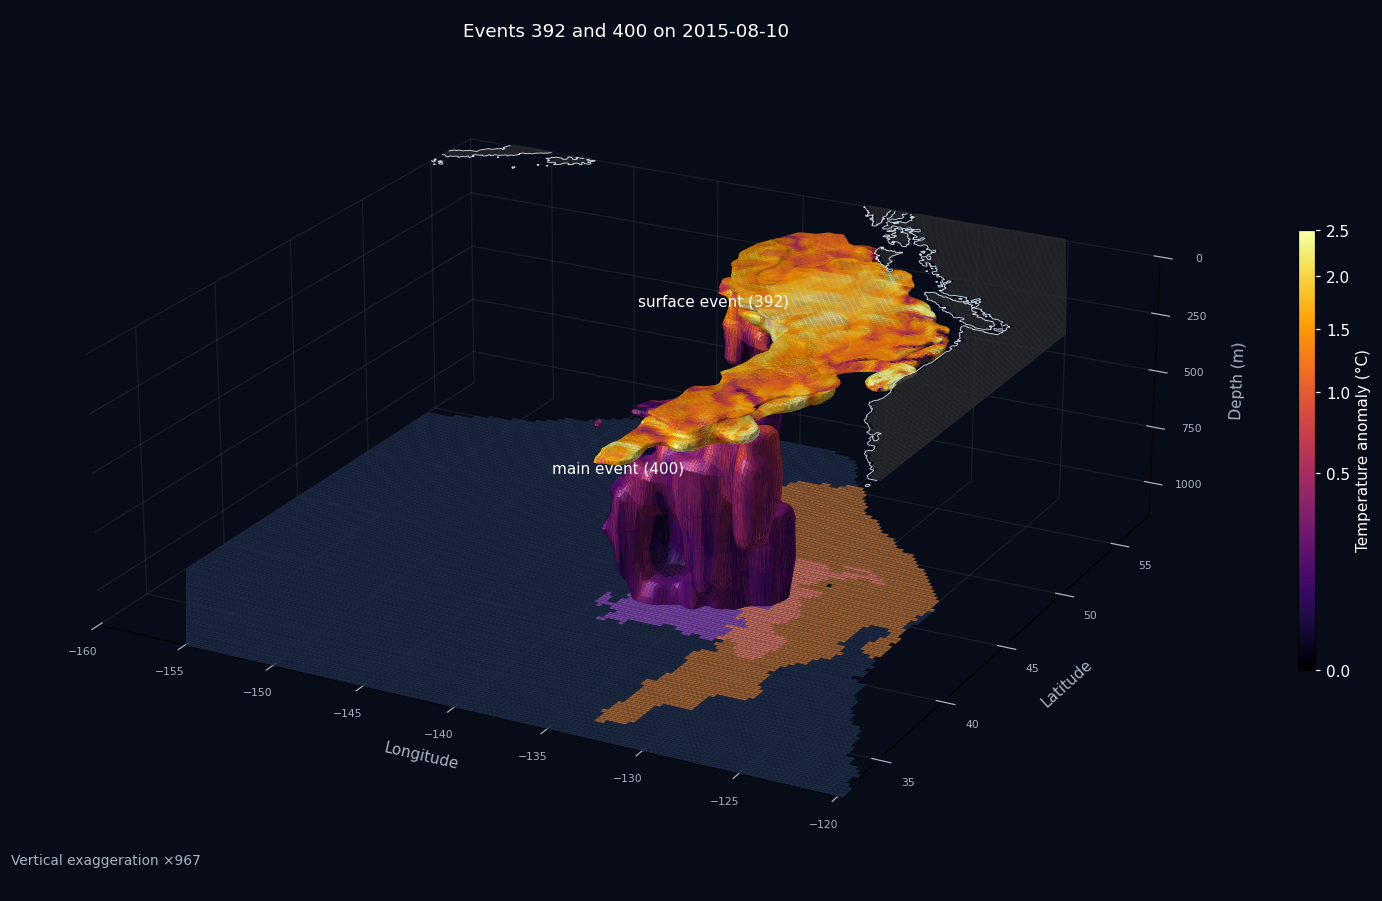

Isosurfaces: the peak: 0.3 min, peak worker memory 7.6 GB of 224 GB (largest worker 0.8 of 14.0 GB), client 1.2 GB, spilled 0.0 GB, restarts 0


In [7]:
with monitor.stage("Isosurfaces: the peak"):
    ids_peak, anomaly_peak = load_day(main_peak)
    fig = plt.figure(figsize=(13, 8), dpi=110, facecolor=BACKGROUND)
    ax = draw_scene(fig, [0, 0, 0.9, 1], ids_peak, anomaly_peak, title=f"Events {surface_id} and {main_id} on {main_peak:%Y-%m-%d}")
    add_anomaly_colourbar(fig, [0.92, 0.25, 0.012, 0.5])
    fig.text(0.02, 0.03, f"Vertical exaggeration ×{exaggeration:.0f}", color="#aab4c0", fontsize=9)
    for event_id, label in [(surface_id, "surface event"), (main_id, "main event")]:
        lat_c, lon_c = (float(centroid.sel(component=c, ID=event_id, time=main_peak)) for c in (0, 1))
        ax.text(
            lon_c - 9,
            lat_c,
            -float(depth_centroid.sel(ID=event_id, time=main_peak)),
            f"{label} ({event_id})",
            color="white",
            fontsize=10,
            zorder=10,
        )
    plt.show()

**Life cycle.** Eight days spread evenly over the main event's life, from one camera, so changes in shape and position
can be compared directly.

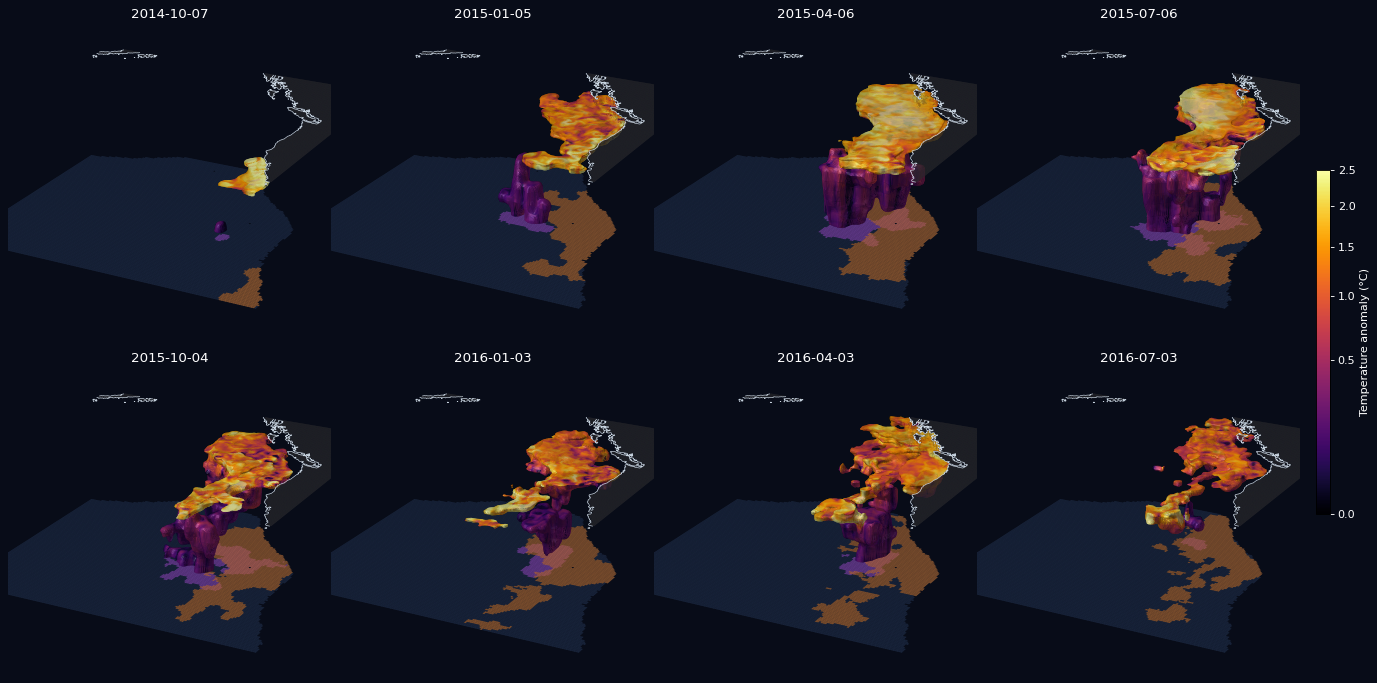

Isosurfaces: life cycle: 2.1 min, peak worker memory 7.0 GB of 224 GB (largest worker 0.5 of 14.0 GB), client 2.2 GB, spilled 0.0 GB, restarts 0


In [8]:
start, end = pd.Timestamp(time_start.sel(ID=main_id).values), pd.Timestamp(time_end.sel(ID=main_id).values)
life_days = pd.date_range(start, end, periods=8).normalize()

with monitor.stage("Isosurfaces: life cycle"):
    fig = plt.figure(figsize=(17, 8.6), dpi=80, facecolor=BACKGROUND)
    for n, day in enumerate(life_days):
        rect = [(n % 4) / 4 * 0.95, 0.5 - 0.5 * (n // 4), 0.95 / 4, 0.5]
        draw_scene(fig, rect, *load_day(day), title=f"{day:%Y-%m-%d}", zoom=1.35, axes_visible=False)
    add_anomaly_colourbar(fig, [0.962, 0.25, 0.01, 0.5])
    plt.show()

## 4. Heat Content and What the Surface Misses

These numbers need a volume, so a surface tracker cannot produce them. The **excess heat content** is
$\rho c_p \int T' \, dV$ over the event's voxels, with $T'$ the anomaly. A voxel is **hidden** when no tracked event is at
the surface level of its column. Testing the raw `extreme_events` at the surface instead raises the lifetime fractions in
the table, from 0.39 to 0.45 for the main event and from 0.57 to 0.66 for the second. The same pass over the event's life
gives the anomaly profile against time and the maps in the sections below.

In [9]:
rho_cp = 1025.0 * 3990.0  # J m^-3 K^-1, seawater


def event_metrics(event_id):
    """Lazy per-day, per-level and per-column statistics of one event over its lifetime."""
    lifetime = slice(time_start.sel(ID=event_id).values, time_end.sel(ID=event_id).values)
    # One task holds a whole 25-day tile, so on a larger domain shorten the time chunk in proportion.
    layout = {"time": 25, "depth": -1, "lat": -1, "lon": -1}
    ids = events_ds.ID_field.sel(time=lifetime).chunk(layout)
    anomaly = extremes_ds.dat_anomaly.sel(time=lifetime).chunk(layout)
    in_event = ids == event_id
    anomaly_in_event = anomaly.where(in_event)
    in_column = in_event.any("depth")
    occupied_area = cell_area.where(in_event).sum(["lat", "lon"])
    day_of_life = xr.DataArray(np.arange(ids.sizes["time"]), dims="time", coords={"time": ids.time})
    return xr.Dataset(
        {
            "heat": rho_cp * (anomaly_in_event * cell_volume).sum(["depth", "lat", "lon"]),
            "volume": cell_volume.where(in_event).sum(["depth", "lat", "lon"]),
            "hidden": cell_volume.where(in_event & (ids.isel(depth=0, drop=True) == 0)).sum(["depth", "lat", "lon"]),
            "profile": (anomaly_in_event * cell_area).sum(["lat", "lon"]) / occupied_area.where(occupied_area > 0),
            "days_occupied": in_column.sum("time"),
            "deepest": in_event.depth.where(in_event).max(["time", "depth"]),
            "first_day": day_of_life.where(in_column).min("time"),
            "column_heat": rho_cp * (anomaly_in_event * thickness).sum("depth").max("time"),
        }
    )


with monitor.stage("Analysis: event metrics"):
    main_metrics, surface_metrics = dask.compute(event_metrics(main_id), event_metrics(surface_id))

zettajoule = 1e21
rows = {}
for name, event_id, metrics in [("main", main_id, main_metrics), ("surface", surface_id, surface_metrics)]:
    rows[f"{name} ({event_id})"] = {
        "peak heat (ZJ)": float(metrics.heat.max()) / zettajoule,
        "peak heat date": str(metrics.heat.idxmax("time").values)[:10],
        "peak volume (1e15 m3)": float(metrics.volume.max()) / 1e15,
        "mean anomaly at peak heat (°C)": float(metrics.heat.max() / rho_cp / metrics.volume.sel(time=metrics.heat.idxmax("time"))),
        "mean hidden fraction": float(metrics.hidden.sum() / metrics.volume.sum()),
    }
pd.DataFrame(rows).T.round(3)

Analysis: event metrics: 1.0 min, peak worker memory 75.5 GB of 224 GB (largest worker 9.3 of 14.0 GB), client 2.2 GB, spilled 0.0 GB, restarts 0


,peak heat (ZJ),peak heat date,peak volume (1e15 m3),mean anomaly at peak heat (°C),mean hidden fraction
main (400),0.380102,2015-07-22,0.287631,0.337969,0.394178
surface (392),1.078072,2015-07-09,0.159079,1.687607,0.573121


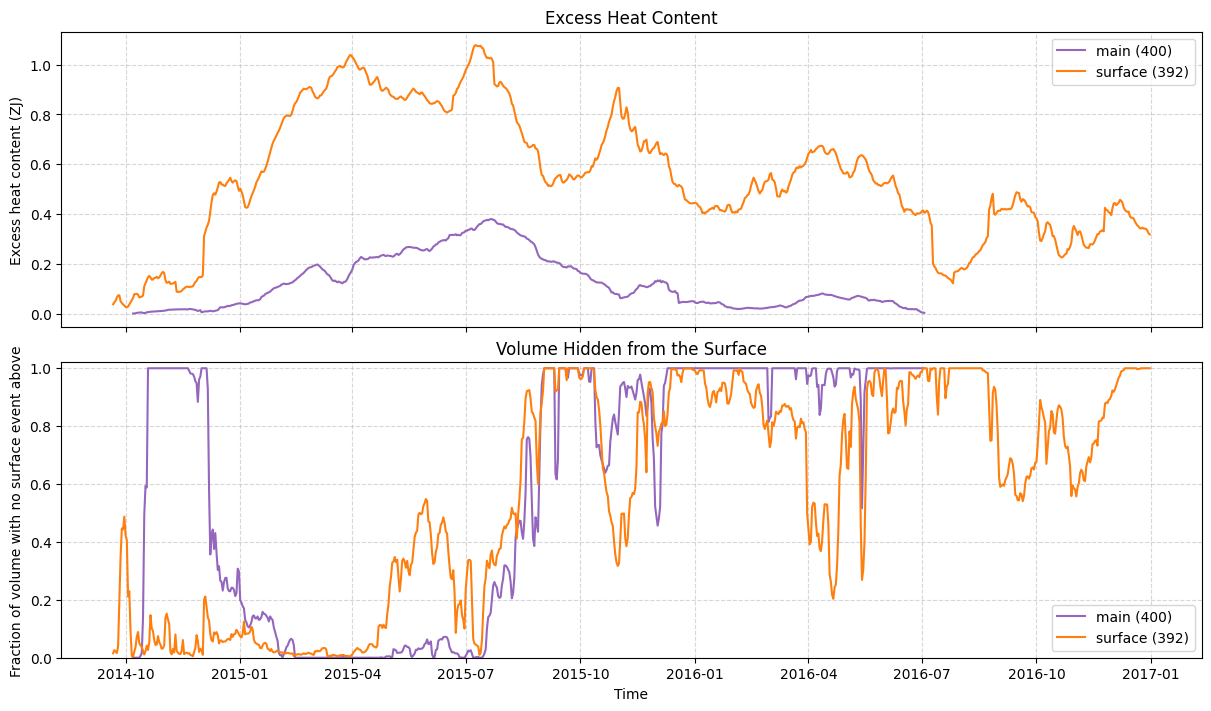

In [10]:
fig, (ax_heat, ax_hidden) = plt.subplots(2, 1, figsize=(12, 7), sharex=True, layout="constrained")
for name, event_id, metrics, colour in [
    ("main", main_id, main_metrics, "tab:purple"),
    ("surface", surface_id, surface_metrics, "tab:orange"),
]:
    ax_heat.plot(metrics.time, metrics.heat / zettajoule, color=colour, label=f"{name} ({event_id})")
    ax_hidden.plot(metrics.time, metrics.hidden / metrics.volume, color=colour, label=f"{name} ({event_id})")
ax_heat.set(ylabel="Excess heat content (ZJ)", title="Excess Heat Content")
ax_hidden.set(
    ylabel="Fraction of volume with no surface event above", ylim=(0, 1.02), xlabel="Time", title="Volume Hidden from the Surface"
)
for ax in (ax_heat, ax_hidden):
    ax.grid(True, linestyle="--", alpha=0.5)
    ax.legend()
plt.show()

Volume-weighted over each quarter, the main event is 2-3% hidden in the first half of 2015, about 45% in the third quarter
and above 97% in each quarter from January 2016. The slab is 2% hidden in the first quarter of 2015, 57% in the third and
71-88% through 2016. Its top is at the surface on 81% of days from July 2015, but the surface level covers a median 95% of
its footprint in the first quarter of 2015 and 3-20% from the fourth. On the main event's peak day, 42% of its volume and
50% of the slab's are hidden.

## 5. Inside the Event

The area-mean anomaly inside each event at every level, against time, with the event's top, volume centroid and bottom
drawn over it. The depth axis is linear, so the thin upper levels take little room.

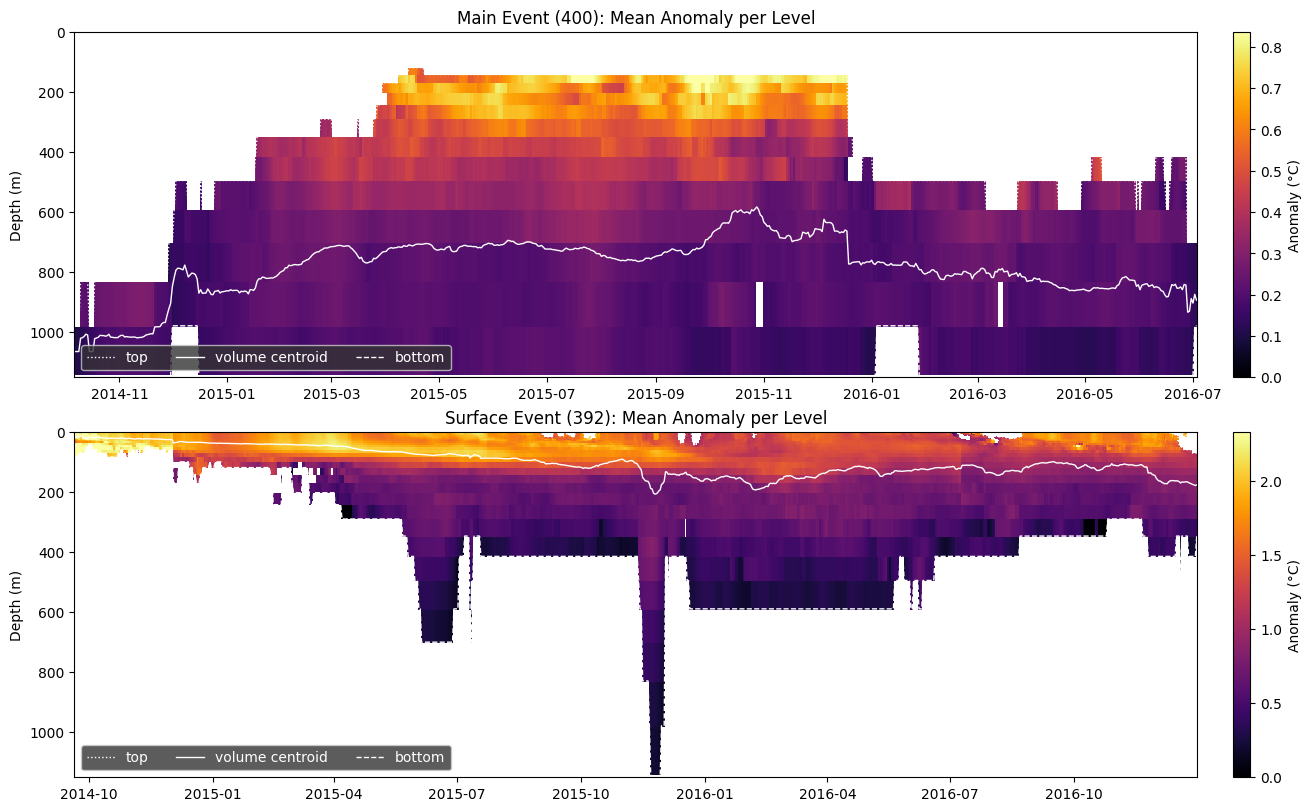

In [11]:
fig, axes = plt.subplots(2, 1, figsize=(13, 8), layout="constrained")
for ax, name, event_id, metrics in [(axes[0], "Main", main_id, main_metrics), (axes[1], "Surface", surface_id, surface_metrics)]:
    limit = float(metrics.profile.quantile(0.99))
    mesh = ax.pcolormesh(metrics.time, metrics.depth, metrics.profile.T, cmap="inferno", vmin=0, vmax=limit, shading="nearest")
    lifetime = {"time": metrics.time}
    for series, style, label in [(depth_top, ":", "top"), (depth_centroid, "-", "volume centroid"), (depth_bottom, "--", "bottom")]:
        ax.plot(metrics.time, series.sel(ID=event_id).sel(**lifetime), color="white", linestyle=style, linewidth=1, label=label)
    ax.set(ylim=(floor_depth, 0), ylabel="Depth (m)", title=f"{name} Event ({event_id}): Mean Anomaly per Level")
    ax.legend(loc="lower left", ncol=3, facecolor="0.2", labelcolor="white")
    fig.colorbar(mesh, ax=ax, label="Anomaly (°C)", pad=0.01)
plt.show()

## 6. The Footprint of a Lifetime

Each column of the map summarised over the main event's whole life: the day it first arrived, how many days it stayed,
the deepest level it reached, and the largest excess heat the column held per square metre.

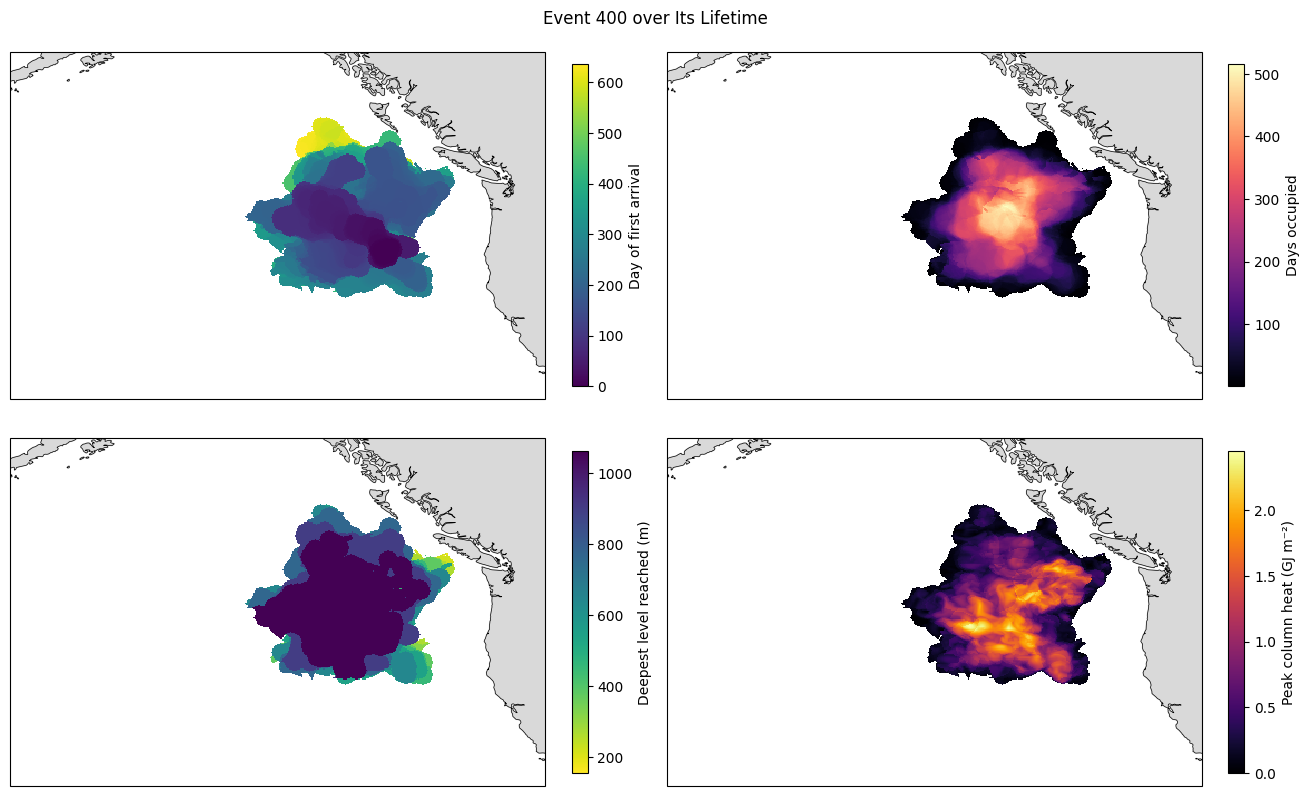

In [12]:
panels = [
    (main_metrics.first_day, "Day of first arrival", "viridis"),
    (main_metrics.days_occupied.where(main_metrics.days_occupied > 0), "Days occupied", "magma"),
    (main_metrics.deepest, "Deepest level reached (m)", "viridis_r"),
    ((main_metrics.column_heat / 1e9).where(main_metrics.days_occupied > 0), "Peak column heat (GJ m⁻²)", "inferno"),
]
fig, axes = plt.subplots(2, 2, figsize=(13, 8), subplot_kw={"projection": ccrs.PlateCarree()}, layout="constrained")
for ax, (field, label, cmap) in zip(axes.flat, panels):
    mesh = ax.pcolormesh(field.lon, field.lat, field, cmap=cmap, transform=ccrs.PlateCarree(), rasterized=True)
    ax.add_feature(cfeature.LAND, color="0.85")
    ax.coastlines(linewidth=0.5)
    ax.set_extent([box_lon[0], box_lon[-1], box_lat[0], box_lat[-1]], crs=ccrs.PlateCarree())
    fig.colorbar(mesh, ax=ax, label=label, shrink=0.85)
fig.suptitle(f"Event {main_id} over Its Lifetime")
plt.show()

## 7. Sections through the Peak

Two vertical sections through the main event's centroid on its peak day. The colours are the anomaly and the contours
outline the two events. On both sections the main event starts below 200 m and the slab lies mostly to one side, overlapping
its main body by less than 2° in longitude and in latitude. Just over half of the event voxels above 100 m on these sections belong to a
third event, 437.

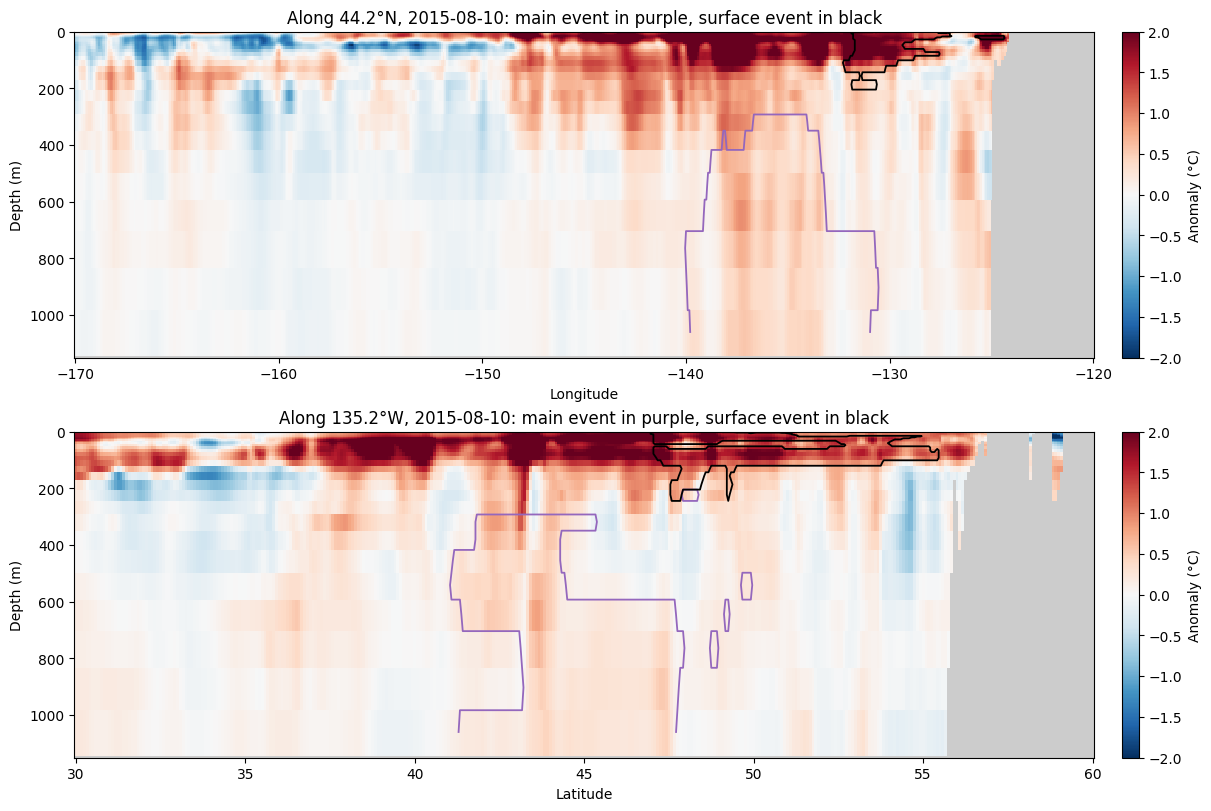

In [13]:
main_lat = float(centroid.sel(component=0, ID=main_id, time=main_peak))
main_lon = float(centroid.sel(component=1, ID=main_id, time=main_peak))
anomaly_day = extremes_ds.dat_anomaly.sel(time=main_peak)
ids_day = events_ds.ID_field.sel(time=main_peak)

fig, axes = plt.subplots(2, 1, figsize=(12, 8), layout="constrained")
sections = [
    (dict(lat=main_lat), "lon", f"Along {main_lat:.1f}°N", "Longitude"),
    (dict(lon=main_lon), "lat", f"Along {abs(main_lon):.1f}°W", "Latitude"),
]
for ax, (where, along, title, xlabel) in zip(axes, sections):
    anomaly_section = anomaly_day.sel(**where, method="nearest").compute()
    ids_section = ids_day.sel(**where, method="nearest").compute()
    mesh = ax.pcolormesh(
        anomaly_section[along], anomaly_section.depth, anomaly_section, cmap="RdBu_r", vmin=-2, vmax=2, shading="nearest"
    )
    for event_id, colour in [(main_id, "tab:purple"), (surface_id, "black")]:
        ax.contour(
            ids_section[along],
            ids_section.depth,
            (ids_section == event_id).astype(int),
            levels=[0.5],
            colors=colour,
            linewidths=1.3,
        )
    ax.set_facecolor("0.8")
    ax.set(
        ylim=(floor_depth, 0),
        ylabel="Depth (m)",
        xlabel=xlabel,
        title=f"{title}, {main_peak:%Y-%m-%d}: main event in purple, surface event in black",
    )
    fig.colorbar(mesh, ax=ax, label="Anomaly (°C)", pad=0.01)
plt.show()

## 8. Tracks and Vertical Extent

On the left, the daily volume-weighted centroid of each event, with marker size following volume and colour following
the date. On the right, the depth range each event covers through time, with the centroid as a line.

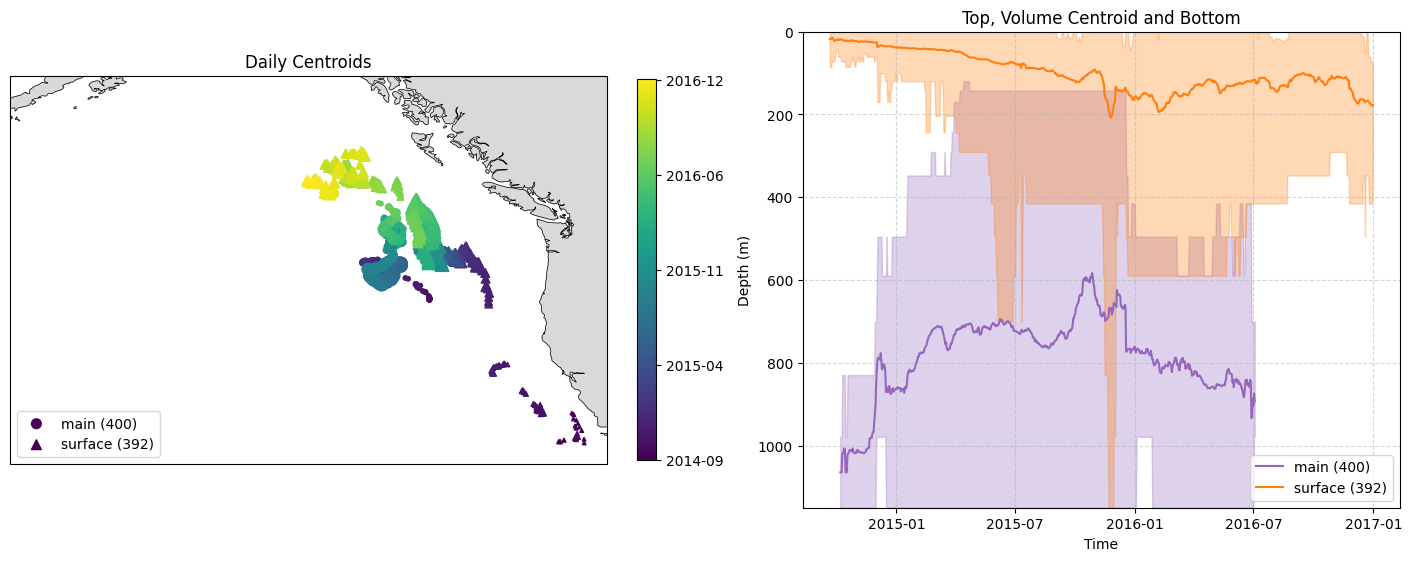

In [14]:
fig = plt.figure(figsize=(14, 5.5), layout="constrained")
ax_map = fig.add_subplot(1, 2, 1, projection=ccrs.PlateCarree())
ax_depth = fig.add_subplot(1, 2, 2)
all_dates = pd.date_range(min(time_start.sel(ID=[main_id, surface_id]).values), max(time_end.sel(ID=[main_id, surface_id]).values))
for name, event_id, marker, colour in [("main", main_id, "o", "tab:purple"), ("surface", surface_id, "^", "tab:orange")]:
    series = volume.sel(ID=event_id).dropna("time")
    series = series.where(series > 0, drop=True)
    days = (series.time.values - all_dates[0].to_datetime64()) / np.timedelta64(1, "D")
    path = ax_map.scatter(
        centroid.sel(component=1, ID=event_id, time=series.time),
        centroid.sel(component=0, ID=event_id, time=series.time),
        c=days,
        s=4 + 90 * series / series.max(),
        marker=marker,
        cmap="viridis",
        vmin=0,
        vmax=len(all_dates),
        transform=ccrs.PlateCarree(),
        label=f"{name} ({event_id})",
    )
    ax_depth.fill_between(
        series.time.values,
        depth_top.sel(ID=event_id, time=series.time),
        depth_bottom.sel(ID=event_id, time=series.time),
        color=colour,
        alpha=0.3,
    )
    ax_depth.plot(series.time.values, depth_centroid.sel(ID=event_id, time=series.time), color=colour, label=f"{name} ({event_id})")
ax_map.add_feature(cfeature.LAND, color="0.85")
ax_map.coastlines(linewidth=0.5)
ax_map.set_extent([box_lon[0], box_lon[-1], box_lat[0], box_lat[-1]], crs=ccrs.PlateCarree())
ax_map.legend(loc="lower left")
ax_map.set_title("Daily Centroids")
colourbar = fig.colorbar(path, ax=ax_map, shrink=0.8)
ticks = np.linspace(0, len(all_dates) - 1, 5).astype(int)
colourbar.set_ticks(ticks, labels=[f"{all_dates[t]:%Y-%m}" for t in ticks])
ax_depth.set(ylim=(floor_depth, 0), ylabel="Depth (m)", xlabel="Time", title="Top, Volume Centroid and Bottom")
ax_depth.xaxis.set_major_locator(mdates.MonthLocator(bymonth=(1, 7)))
ax_depth.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
ax_depth.grid(True, linestyle="--", alpha=0.5)
ax_depth.legend()
plt.show()

## 9. Mergers Shared with Other Events

Events that touch keep their own identities, and the tracker partitions the connected region between them, logging one row
in `merges_ds` for each merger, with its parent objects and the child objects after the partition. Those rows contain
per-day object IDs, not event IDs, and `global_ID` maps one to the other. Of the 17,999 parent IDs, 46 do not resolve and
are skipped. Each mark below is a day on which the main event and another event were parents in the same merger, for the
partners it shared the most days with, coloured by the depth of that partner's centroid. Two parents of one merger need
not touch each other. The two events are adjacent at half of these marks, on that day or the day before, and four of
the twelve (414, 407, 633 and 512) are never adjacent to the main event at a mark.

Event 400 shared 5266 merger records with 83 other events
Surface event 392: 462 days with a shared merger


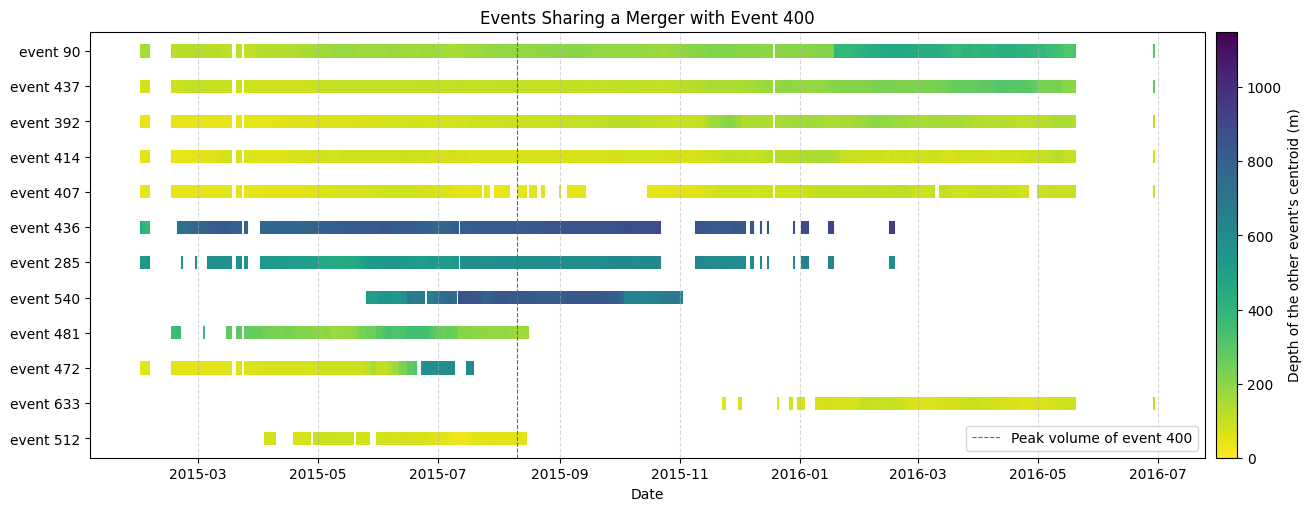

In [15]:
parents, merge_times = merges_ds.parent_IDs.values, merges_ds.merge_time.values
global_id = events_ds.global_ID.load()  # (time, ID), the object ID of each event on each day
time_index = pd.Index(events_ds.time.values)

# Object IDs repeat between days, so the lookup is keyed by day. A merger's parents are objects of the day before.
object_to_event = {}
for day, row in enumerate(global_id.values):
    for position in np.flatnonzero(row > 0):
        object_to_event[(day, int(row[position]))] = int(global_id.ID.values[position])

records = []
for merge_time, row in zip(merge_times, parents):
    day = time_index.get_loc(merge_time) - 1
    parent_events = {object_to_event.get((day, int(parent))) for parent in row[row > 0]} - {None}
    if main_id in parent_events:
        records += [(merge_time, partner) for partner in parent_events - {main_id}]

partners = pd.DataFrame(records, columns=["time", "ID"])
partners["peak volume"] = volume.max("time").sel(ID=partners.ID.values).values
partners["depth"] = [float(depth_centroid.sel(ID=event, time=day)) for day, event in zip(partners.time, partners.ID)]

shared_days = partners.ID.value_counts()
top_partners = shared_days.index[:12]
print(f"Event {main_id} shared {len(partners)} merger records with {partners.ID.nunique()} other events")
print(f"Surface event {surface_id}: {shared_days.get(surface_id, 0)} days with a shared merger")

fig, ax = plt.subplots(figsize=(13, 5), layout="constrained")
for row, partner in enumerate(top_partners):
    partner_marks = partners[partners.ID == partner]
    marks = ax.scatter(
        partner_marks.time,
        np.full(len(partner_marks), row),
        c=partner_marks.depth,
        cmap="viridis_r",
        vmin=0,
        vmax=floor_depth,
        marker="|",
        s=90,
    )
ax.set_yticks(range(len(top_partners)), [f"event {partner}" for partner in top_partners])
ax.invert_yaxis()
ax.axvline(main_peak, color="0.4", linewidth=0.8, linestyle="--", label=f"Peak volume of event {main_id}")
ax.set(xlabel="Date", title=f"Events Sharing a Merger with Event {main_id}")
ax.grid(True, axis="x", linestyle="--", alpha=0.5)
ax.legend(loc="lower right")
fig.colorbar(marks, ax=ax, label="Depth of the other event's centroid (m)", pad=0.01)
plt.show()

## 10. The `plotX` 4-D Helpers

The four helpers in `marEx.plotX` cover the standard views without any of the code above. Each selects the time steps,
levels or event it needs from the lazy `ID_field` before loading.

**Per-level maps.** All events at the main event's peak, on six levels. Other events are drawn in grey and the main
event in red, so it appears only on the levels it reaches.

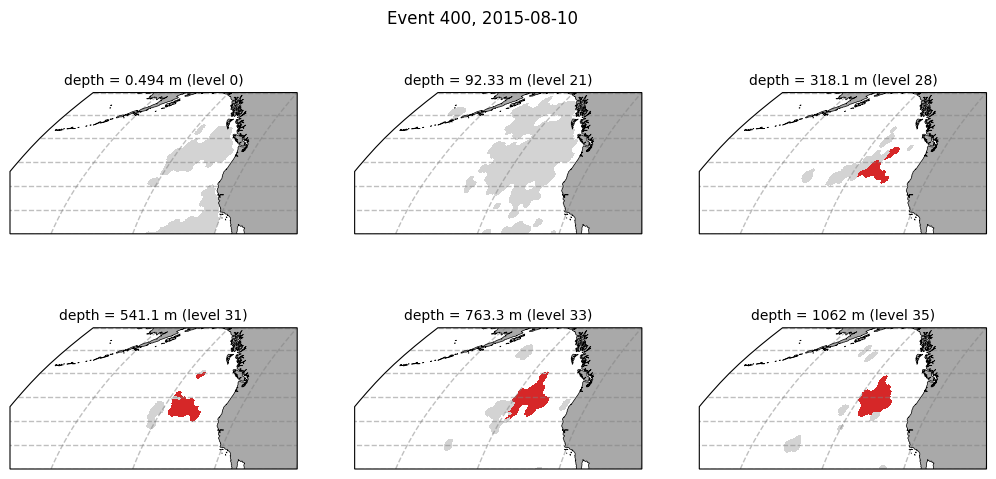

In [16]:
levels = [int(np.abs(events_ds.depth.values - depth).argmin()) for depth in (0, 100, 300, 500, 750, 1000)]
fig = plot_event_levels(events_ds, main_peak, levels, zdim="depth", event_id=main_id)

**Depth-time section.** The volume of the main event at each level through its life.

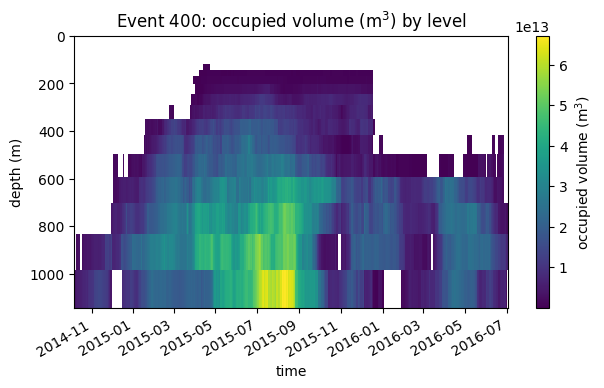

In [17]:
fig = plot_event_depth_time(events_ds, main_id, zdim="depth", quantity="volume", cell_volume=cell_volume.fillna(0.0))

**Event summary.** The main event's volume, the depth of its centroid and its vertical extent. A dashed line
marks the first day of each unbroken run of days with a merger. The event merged on 551 of its 636 days, and the last run
lasts 467 days, from 2015-03-25 to the event's end.

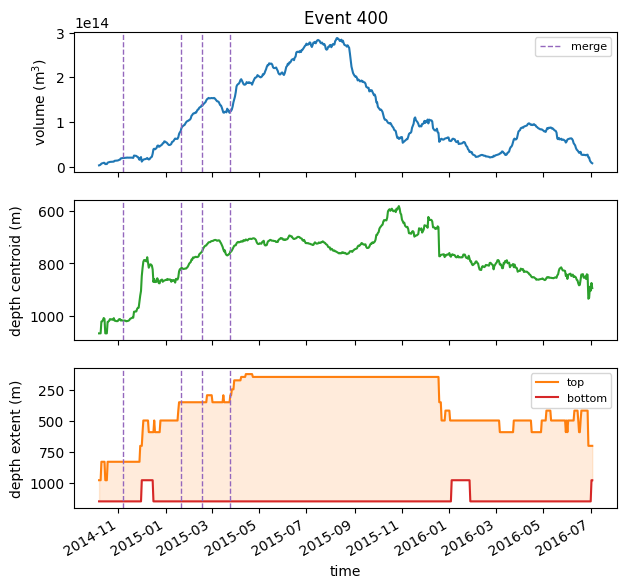

In [18]:
fig = plot_event_summary(events_ds, main_id, merges_ds)

## 11. Movies

**Events as isosurfaces.** Every third day of the main event's life, with a slow camera drift. The inset follows the excess
heat content of both events. Each frame is one dask task. `ffmpeg` encodes the frames, and the player shows the copy in
the repository's `media/` folder.

In [19]:
def render_frame(n, day, ids, anomaly, frame_dir, heat_series):
    plt.switch_backend("Agg")
    camera = (22, -62 + 16 * np.sin(2 * np.pi * n / 240))
    fig = plt.figure(figsize=(12.8, 7.2), dpi=100, facecolor=BACKGROUND)
    draw_scene(fig, [0, 0, 0.92, 1], ids, anomaly, title=f"Events {surface_id} and {main_id}: {day:%Y-%m-%d}", camera=camera)
    add_anomaly_colourbar(fig, [0.93, 0.25, 0.012, 0.5])
    inset = fig.add_axes([0.07, 0.74, 0.26, 0.17], facecolor="none")
    for times, values, colour in heat_series:
        inset.plot(times, values, color=colour, linewidth=1)
    inset.axvline(day, color="white", linewidth=0.8)
    inset.set_ylabel("Excess heat (ZJ)", color="white", fontsize=8)
    inset.tick_params(colors="white", labelsize=7)
    for side in ("top", "right"):
        inset.spines[side].set_visible(False)
    for side in ("left", "bottom"):
        inset.spines[side].set_color("white")
    inset.xaxis.set_major_locator(plt.matplotlib.dates.YearLocator())
    fig.savefig(Path(frame_dir) / f"time_{n:04d}.jpg", facecolor=BACKGROUND, pil_kwargs={"quality": 92})
    plt.close(fig)


movie_days = pd.date_range(start, end, freq=f"{movie_every}D")
frame_dir = plot_dir / "frames_movie_events_4d"
frame_dir.mkdir(exist_ok=True)
heat_series = [
    (main_metrics.time.values, main_metrics.heat.values / zettajoule, "#c060f0"),
    (surface_metrics.time.values, surface_metrics.heat.values / zettajoule, "#ff8c26"),
]
ids_box = events_ds.ID_field.sel(time=movie_days, **render_box)
anomaly_box = extremes_ds.dat_anomaly.sel(time=movie_days, **render_box)
frames = [
    dask.delayed(render_frame)(n, day, ids_box.isel(time=n).data, anomaly_box.isel(time=n).data, str(frame_dir), heat_series)
    for n, day in enumerate(movie_days)
]
with monitor.stage("Movie: events as isosurfaces"):
    dask.compute(*frames)
    movie_events = plot_dir / "movie_events_4d.mp4"
    if shutil.which("ffmpeg"):
        subprocess.run(
            ["ffmpeg", "-hide_banner", "-loglevel", "error", "-y", "-framerate", "15", "-i", str(frame_dir / "time_%04d.jpg")]
            + [
                "-c:v",
                "libx264",
                "-preset",
                "slow",
                "-crf",
                "24",
                "-pix_fmt",
                "yuv420p",
                "-movflags",
                "+faststart",
                str(movie_events),
            ],
            check=True,
        )
    shutil.rmtree(frame_dir)
print(f"{len(movie_days)} frames, {movie_events if movie_events.exists() else 'no movie: ffmpeg is not installed'}")
Video(url="../../media/movie_events_4d.mp4", width=800, height=450)

Movie: events as isosurfaces: 3.1 min, peak worker memory 23.0 GB of 224 GB (largest worker 3.1 of 14.0 GB), client 2.2 GB, spilled 0.0 GB, restarts 0
212 frames, plots/movie_events_4d.mp4


**Footprint of all events.** `animate_event_levels` projects every event onto the map and colours it by the depth of the
shallowest level it reaches, here for the 181 days around the main event's peak. A movie needs `ffmpeg`, and without it the
helper returns `None`.

In [20]:
movie_window = slice(main_peak - pd.Timedelta(days=90), main_peak + pd.Timedelta(days=90))
with monitor.stage("Movie: event footprint depth"):
    movie = animate_event_levels(
        events_ds.sel(time=movie_window),
        zdim="depth",
        levels="footprint",
        plot_dir=plot_dir,
        file_name="movie_event_footprint_4d",
    )
print(f"movie written to {movie}" if movie else "no movie: ffmpeg is not installed on this machine")
Video(url="../../media/movie_event_footprint_4d.mp4", width=640, height=480)

2026-11-02 22:21:06 - marEx - INFO - [PID:537543] - MarEx logging configured - Level: INFO, Mode: normal
2026-11-02 22:21:06 - marEx - INFO - [PID:537534] - MarEx logging configured - Level: INFO, Mode: normal
2026-11-02 22:21:06 - marEx - INFO - [PID:537502] - MarEx logging configured - Level: INFO, Mode: normal
2026-11-02 22:21:06 - marEx - INFO - [PID:537510] - MarEx logging configured - Level: INFO, Mode: normal
2026-11-02 22:21:06 - marEx - INFO - [PID:537518] - MarEx logging configured - Level: INFO, Mode: normal
2026-11-02 22:21:06 - marEx - INFO - [PID:537553] - MarEx logging configured - Level: INFO, Mode: normal
2026-11-02 22:21:06 - marEx - INFO - [PID:537551] - MarEx logging configured - Level: INFO, Mode: normal
2026-11-02 22:21:06 - marEx - INFO - [PID:537546] - MarEx logging configured - Level: INFO, Mode: normal
2026-11-02 22:21:06 - marEx - INFO - [PID:537498] - MarEx logging configured - Level: INFO, Mode: normal
2026-11-02 22:21:06 - marEx - INFO - [PID:537538] - Mar

2026-11-02 22:21:07 - marEx - INFO - [PID:537526] - MarEx logging configured - Level: INFO, Mode: normal
2026-11-02 22:21:07 - marEx - INFO - [PID:537515] - MarEx logging configured - Level: INFO, Mode: normal
2026-11-02 22:21:07 - marEx - INFO - [PID:537494] - MarEx logging configured - Level: INFO, Mode: normal


Movie: event footprint depth: 0.2 min, peak worker memory 17.0 GB of 224 GB (largest worker 1.2 of 14.0 GB), client 2.2 GB, spilled 0.0 GB, restarts 0
movie written to plots/movie_event_footprint_4d.mp4


## Wall Time and Memory

Peak memory summed over workers, the largest single worker, and the client (this kernel), per stage.

In [21]:
monitor.summary()

,wall (min),peak worker memory (GB),peak per worker (GB),peak client memory (GB),peak spilled to disk (GB),worker restarts
stage,,,,,,
Isosurfaces: the peak,0.33,7.62,0.75,1.25,0.0,0
Isosurfaces: life cycle,2.10,6.98,0.51,2.19,0.0,0
Analysis: event metrics,1.03,75.49,9.28,2.19,0.0,0
Movie: events as isosurfaces,3.15,22.96,3.08,2.21,0.0,0
Movie: event footprint depth,0.23,17.00,1.16,2.21,0.0,0
total,6.84,75.49,9.28,2.21,0.0,0


In [22]:
client.close()